# 06 · Showdown

All filters, same mower, same data. Four scenarios, from easy to hard:

1. **Tracking**: a good initial guess, landmarks identified.
2. **Uncertain start**: a poor initial guess, short sensor range.
3. **Kidnapped mower**: teleported mid-run, landmarks identified.
4. **Unknown data association**: the sensor does not say which landmark it saw.

Each scenario is repeated over several random seeds. A filter is counted as **lost** when
its median position error over the last 50 steps exceeds 10 units.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import (World, simulate, CompassGpsKF, EKF, UKF, ParticleFilter, run_filter,
                            position_error, position_rmse, nees)
from bayesian_filters import viz
viz.style()

world = World.default()

def summarise(results, run):
    out = {}
    for r in results:
        pe = position_error(r.means, run.truth)
        out[r.name] = dict(err=pe, lost=bool(np.nanmedian(pe[-50:]) > 10) or r.diverged,
                           rmse=position_rmse(r.means, run.truth, skip=20),
                           nees=np.nanmean(nees(r.means, r.covs, run.truth)[20:]),
                           ms=1000 * r.seconds / run.n_steps)
    return out

def table(rows, cols, fmt):
    names = list(rows[0].keys())
    print(f"{'':10s}" + "".join(f"{c:>14s}" for c in cols))
    for n in names:
        vals = [fmt[c](np.mean([r[n][k] for r in rows])) for c, k in cols.items()]
        print(f"{n:10s}" + "".join(f"{v:>14s}" for v in vals))

## 1. Tracking

Initial estimate drawn from $\mathcal N(x_0, P_0)$, $P_0 = \operatorname{diag}(10, 10, 0.05)$, all
four landmarks always visible and identified. The KF uses compass + GPS instead of landmarks
(notebook 02), so its numbers measure a different sensor suite.

In [2]:
P0 = np.diag([10.0, 10.0, 0.05])
rows = []
for seed in range(10):
    run = simulate(world, n_steps=400, seed=seed)
    x0 = run.truth[0] + np.random.default_rng(1000 + seed).multivariate_normal(np.zeros(3), P0)
    filters = [CompassGpsKF.from_world(world, x0, P0), EKF.from_world(world, x0, P0),
               UKF.from_world(world, x0, P0), ParticleFilter(world, 1000, init=(x0, P0), seed=seed)]
    rows.append(summarise([run_filter(f, run) for f in filters], run))
table(rows, {"RMSE": "rmse", "mean NEES": "nees", "ms / step": "ms", "lost (frac)": "lost"},
      {"RMSE": "{:.2f}".format, "mean NEES": "{:.2f}".format, "ms / step": "{:.2f}".format, "lost (frac)": "{:.1f}".format})
print("(NEES should be close to the state dimension: 2 for the KF, 3 for the others)")

                    RMSE     mean NEES     ms / step   lost (frac)
KF                  2.03          1.85          0.03           0.0
EKF                 1.20          3.11          0.09           0.0
UKF                 1.20          3.11          0.14           0.0
PF                  1.28          3.00          0.70           0.0
(NEES should be close to the state dimension: 2 for the KF, 3 for the others)


With the landmarks identified and a decent start, the three landmark filters are equally
accurate and all are consistent. The EKF is the cheapest. **This is the
common case, and the EKF is the right tool for it.**

## 2. Uncertain start

$\sigma_{xy} = 30$, $\sigma_\theta = 0.8$ rad, sensor range 110. The particle filter starts from
the uniform prior over the lawn instead: it needs no guess at all.

                    RMSE     mean NEES   lost (frac)
EKF                 1.98           3.2           0.0
UKF                 1.97           3.1           0.0
PF                  2.29          11.5           0.0


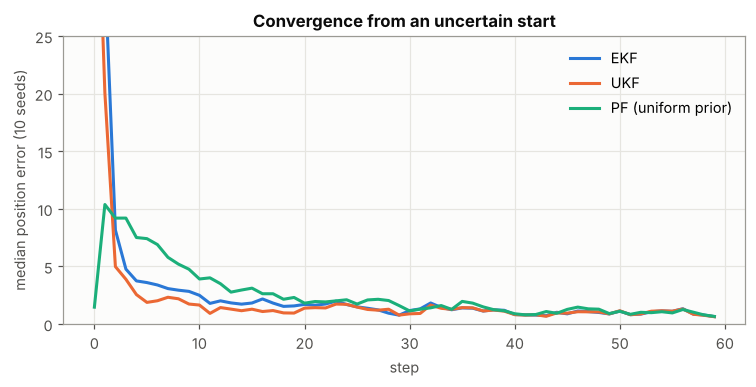

In [3]:
world_lr = World.default(max_range=110)
P0u = np.diag([30.0**2, 30.0**2, 0.8**2])
rows, errs = [], {"EKF": [], "UKF": [], "PF": []}
for seed in range(10):
    run = simulate(world_lr, n_steps=200, seed=seed)
    x0 = run.truth[0] + np.random.default_rng(100 + seed).multivariate_normal(np.zeros(3), P0u)
    filters = [EKF.from_world(world_lr, x0, P0u), UKF.from_world(world_lr, x0, P0u),
               ParticleFilter(world_lr, 5000, init="global", seed=seed)]
    s = summarise([run_filter(f, run) for f in filters], run)
    rows.append(s)
    for k in errs:
        errs[k].append(s[k]["err"])
table(rows, {"RMSE": "rmse", "mean NEES": "nees", "lost (frac)": "lost"},
      {"RMSE": "{:.2f}".format, "mean NEES": "{:.1f}".format, "lost (frac)": "{:.1f}".format})

fig, ax = plt.subplots(figsize=(8, 3.4))
for k, e in errs.items():
    ax.plot(np.median(e, 0)[:60], color=viz.color(k), label=k + (" (uniform prior)" if k == "PF" else ""))
ax.set_ylim(0, 25); ax.set_xlabel("step"); ax.set_ylabel("median position error (10 seeds)")
ax.legend(); ax.set_title("Convergence from an uncertain start")
plt.show()

Everybody converges. The PF, starting from *no* information, takes longer to settle than
the Kalman filters, which were handed a guess. After step 20 the EKF and UKF are consistent,
but the PF's mean NEES is about 11, nearly four times the expected 3. That is the cost of
**sample impoverishment** (notebook 05): after the first update collapsed the cloud, the
particles are too few and too alike, and the cloud claims more precision than it has.

## 3. The kidnapped mower (landmarks identified)

At step 200 the mower is moved to $(100, -100)$ and turned to face west.

steps until the error stays below 10 after the kidnapping (8 seeds):
  EKF  median    64   all: [107, 119, 29, 61, 82, 58, 21, 67]
  UKF  median    64   all: [107, 119, 29, 61, 82, 58, 21, 67]
  PF   median    15   all: [13, 76, 15, 14, 15, 8, 25, 24]


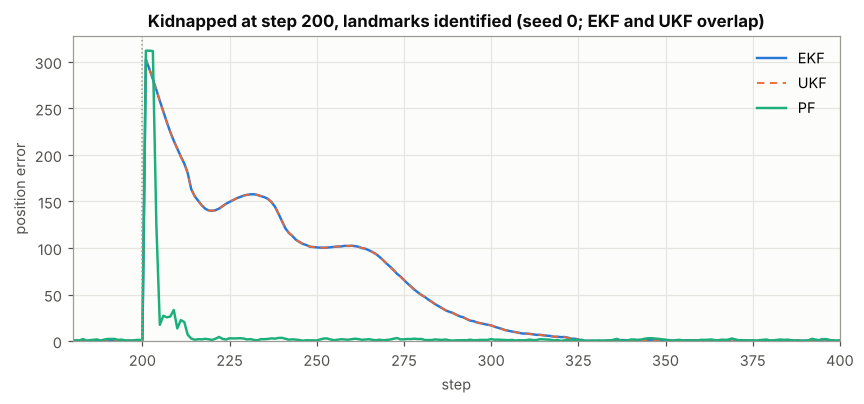

In [4]:
kid = (200, (100.0, -100.0, np.pi))

def recovery_steps(err, t_kid, thresh=10.0):
    """Steps after the kidnapping until the error stays below `thresh` for good (NaN: never)."""
    bad = np.flatnonzero(err[t_kid + 1:] >= thresh)
    k = 0 if len(bad) == 0 else bad[-1] + 1
    return k + 1 if k < len(err) - t_kid - 1 else np.nan

rec, ex = {"EKF": [], "UKF": [], "PF": []}, None
for seed in range(8):
    run = simulate(world, n_steps=400, seed=seed, kidnap=kid)
    filters = [EKF.from_world(world, run.truth[0], P0), UKF.from_world(world, run.truth[0], P0),
               ParticleFilter(world, 3000, init=(run.truth[0], P0), roughening=0.5, recovery=(0.001, 0.1), seed=seed)]
    res = [run_filter(f, run) for f in filters]
    for r in res:
        rec[r.name].append(recovery_steps(position_error(r.means, run.truth), kid[0]))
    if seed == 0:
        ex = (run, res)
print("steps until the error stays below 10 after the kidnapping (8 seeds):")
for k, v in rec.items():
    print(f"  {k:4s} median {np.nanmedian(v):5.0f}   all: {[None if np.isnan(x) else int(x) for x in v]}")

run, res = ex
fig, ax = plt.subplots(figsize=(9, 3.6))
for r in res:
    ax.plot(position_error(r.means, run.truth), color=viz.color(r.name), lw=1.6 if r.name != "UKF" else 1.2,
            ls="-" if r.name != "UKF" else (0, (4, 3)), label=r.name)
ax.axvline(kid[0], color=viz.MUTED, ls=":", lw=1)
ax.set_xlim(180, 400); ax.set_ylim(bottom=0); ax.legend(); ax.set_xlabel("step"); ax.set_ylabel("position error")
ax.set_title("Kidnapped at step 200, landmarks identified (seed 0; EKF and UKF overlap)")
plt.show()

A surprise: the **Kalman filters do recover**, every time, but slowly. With every landmark
identified, each measurement is close to a full position fix, and the likelihood has a single
peak. Even a wildly wrong Gaussian is pulled towards it, step after step. The pull is slow
because the filter's covariance is small (it was confident before the kidnapping), so it
keeps trusting its prediction and moves only a little at each update. The particle filter
instead *re-samples the lawn* (augmented MCL) and jumps to the new pose in a few steps.

The real lesson is that **identified landmarks make the problem unimodal**, the situation
in which a Gaussian filter is at home. Take the identities away and the picture changes.

## 4. Unknown data association

Now the sensor returns a set of $(r, \phi)$ pairs without saying which landmark produced
each one. The EKF must decide the association before it can update. It uses
**nearest-neighbour** association: each measurement is attributed to the landmark whose
predicted measurement is closest in Mahalanobis distance (`association="nearest"`). The PF
uses the mixture likelihood of notebook 05 with augmented MCL. Two sub-cases: an uncertain
start ($\sigma_{xy} = 80$, any heading) and a kidnapping.

In [5]:
P0w = np.diag([80.0**2, 80.0**2, np.pi**2])
lost = {"uncertain start": {"EKF": [], "PF": []}, "kidnapped": {"EKF": [], "PF": []}}
examples = {}
for seed in range(8):
    for case in lost:
        if case == "kidnapped":
            run = simulate(world, n_steps=400, seed=seed, kidnap=kid)
            x0, Pi = run.truth[0], P0
        else:
            run = simulate(world, n_steps=400, seed=seed)
            x0 = run.truth[0] + np.random.default_rng(200 + seed).multivariate_normal(np.zeros(3), P0w)
            Pi = P0w
        filters = [EKF.from_world(world, x0, Pi, association="nearest"),
                   ParticleFilter(world, 3000, init="global", association="unknown", roughening=0.5,
                                  recovery=(0.001, 0.1), seed=seed)]
        res = [run_filter(f, run) for f in filters]
        s = summarise(res, run)
        for k in lost[case]:
            lost[case][k].append(s[k]["lost"])
        if seed == 1:
            examples[case] = (run, res)

print(f"{'':18s}{'EKF (nearest neighbour)':>26s}{'PF (mixture + recovery)':>26s}")
for case, d in lost.items():
    print(f"{case:18s}" + "".join(f"{f'lost {sum(v)} / {len(v)}':>26s}" for v in d.values()))

                     EKF (nearest neighbour)   PF (mixture + recovery)
uncertain start                   lost 4 / 8                lost 0 / 8
kidnapped                         lost 6 / 8                lost 0 / 8


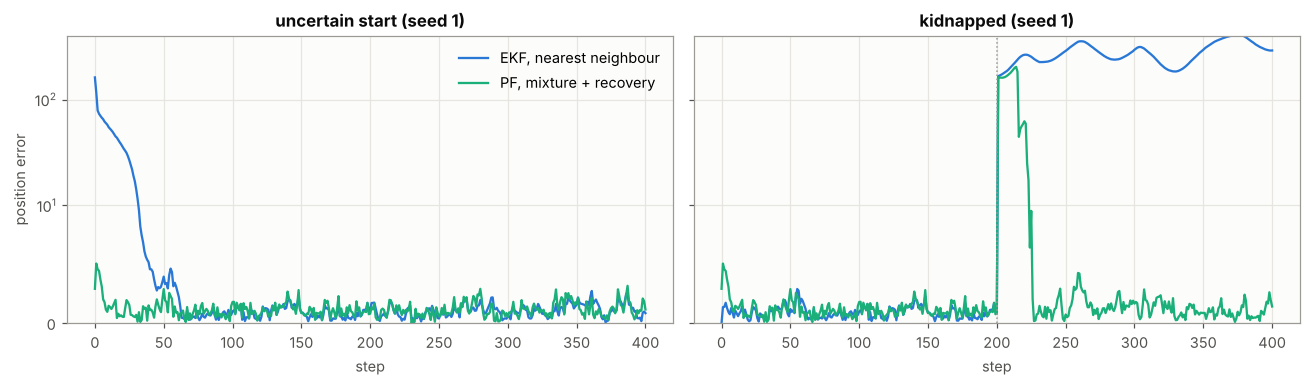

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (case, (run, res)) in zip(axes, examples.items()):
    for r in res:
        ax.plot(position_error(r.means, run.truth), color=viz.color(r.name), lw=1.5,
                label="EKF, nearest neighbour" if r.name == "EKF" else "PF, mixture + recovery")
    if case == "kidnapped":
        ax.axvline(kid[0], color=viz.MUTED, ls=":", lw=1)
    ax.set_title(f"{case} (seed 1)"); ax.set_xlabel("step")
    ax.set_yscale("symlog", linthresh=10); ax.set_ylim(0, 400)
axes[0].set_ylabel("position error"); axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

Without identities the EKF is fragile. As soon as its estimate is off by more than the
spacing of the landmarks, nearest-neighbour association picks the wrong landmark. The update
then pulls the estimate *further* in the wrong direction and shrinks the covariance, which makes
the next wrong association even more likely. Here it was lost in 4 of the 8 uncertain
starts and 6 of the 8 kidnappings. The particle filter
never commits to an association: every particle is scored against every possible one. Random
injection lets it find the mower again after a kidnapping.

## 5. Scorecard

| | KF | EKF | UKF | PF |
|---|---|---|---|---|
| needs | linear model (compass + GPS) | Jacobians | nothing extra | a likelihood you can evaluate |
| tracking, identified landmarks | good | good, cheapest | good | good, ~7x cost |
| uncertain start | — | converges, over-confident at first | converges, honest | no guess needed; slower, over-confident cloud |
| kidnapped, identified landmarks | — | recovers slowly | recovers slowly | recovers fast (with injection) |
| unknown association | — | often lost | (not tested; same association problem) | recovers |
| multimodal belief | no | no | no | yes, but modes can die |

**Choosing a filter**

* The belief is roughly Gaussian and the models are smooth → **EKF**. It is cheap, and its
  Jacobians are worth checking with finite differences (notebook 03).
* Large initial uncertainty, strong non-linearity, or Jacobians that are painful → **UKF**.
* The belief can be multimodal (global localisation, ambiguous or unidentified landmarks,
  kidnapping) and the state is low-dimensional → **particle filter**.
* High-dimensional *and* non-Gaussian → none of the above as they are. Look at Rao–Blackwellised
  particle filters (sample the hard part, Kalman-filter the rest), or at learned models like
  the deep Kalman filters of the follow-up repository.